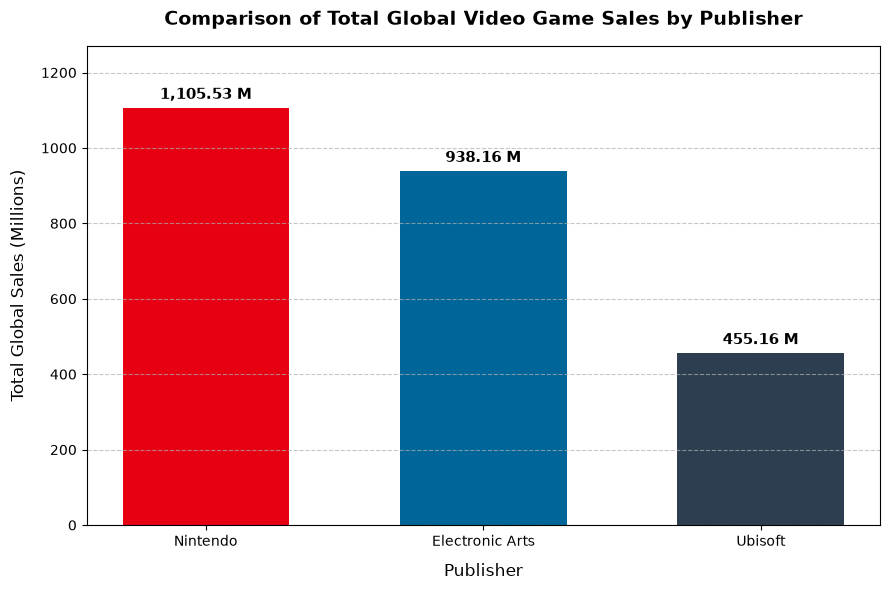

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import io

# 1. โหลดข้อมูลจากไฟล์ CSV (หรือดึงข้อมูลจากข้อความ)
# ในกรณีใช้งานจริง ให้เปลี่ยน io.StringIO(data_string) เป็น 'ชื่อไฟล์.csv' ของคุณ
data_string = """Platform,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
Wii,2006,Nintendo,41.49,29.02,3.77,8.46,82.74
Wii,2008,Nintendo,15.85,12.88,3.79,3.31,35.82
...
""" # ใส่ข้อมูล CSV ของคุณที่นี่

# อ่านข้อมูลเข้ามาใน DataFrame
df = pd.read_excel("Game_data_clean.xlsx") # หรือ pd.read_csv(io.StringIO(data_string))

# 2. รวมยอดขายรวมทั่วโลกแยกตามค่ายเกม (Publisher)
publisher_sales = df.groupby('Publisher')['Global_Sales'].sum().reset_index()

# เรียงลำดับจากยอดขายมากไปน้อยเพื่อความสวยงาม
publisher_sales = publisher_sales.sort_values(by='Global_Sales', ascending=False)

# 3. กำหนดขนาดและสร้างกราฟแท่ง
plt.figure(figsize=(9, 6))
colors = ['#e60012', '#006699', '#2c3e50'] # กำหนดสีประจำค่าย (แดง: Nintendo, ฟ้า: EA, ดำ/เทา: Ubisoft)

bars = plt.bar(publisher_sales['Publisher'], publisher_sales['Global_Sales'], color=colors, width=0.6)

# 4. ตกแต่งกราฟให้สวยงามและอ่านง่าย
plt.title('Comparison of Total Global Video Game Sales by Publisher', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Publisher', fontsize=12, labelpad=10)
plt.ylabel('Total Global Sales (Millions)', fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# เพิ่มตัวเลขยอดขายแสดงบนหัวแท่งกราฟแต่ละแท่ง
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f'{yval:,.2f} M', ha='center', va='bottom', fontsize=11, fontweight='bold')

# ปรับระดับแกน Y ให้มีพื้นที่ว่างด้านบนสำหรับแสดงตัวเลข
plt.ylim(0, max(publisher_sales['Global_Sales']) * 1.15)

# 5. แสดงกราฟ
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd

# 1. โหลดข้อมูลจากไฟล์ของคุณ
df = pd.read_excel("Game_data_clean.xlsx")

# 2. กรองข้อมูลเฉพาะ 3 ค่ายเกมที่ต้องการวิเคราะห์
target_publishers = ["Nintendo", "Electronic Arts", "Ubisoft"]
filtered_df = df[df["Publisher"].isin(target_publishers)].copy()

# 3. แปลงโครงสร้างข้อมูลจากแนวกว้าง (Wide) ให้เป็นแนวตั้ง (Long) เพื่อจัดกลุ่มภูมิภาค
melted_df = pd.melt(
    filtered_df,
    id_vars=["Publisher"],
    value_vars=["NA_Sales", "EU_Sales", "JP_Sales"],
    var_name="Region",
    value_name="Sales",
)

# เปลี่ยนชื่อเรียกภูมิภาคให้เข้าใจง่ายและตรงตามกราฟ
region_mapping = {
    "NA_Sales": "North America (NA)",
    "EU_Sales": "Europe (EU)",
    "JP_Sales": "Japan (JP)",
}
melted_df["Region"] = melted_df["Region"].map(region_mapping)

# 4. คำนวณค่าเฉลี่ย (Mean) และส่วนเบี่ยงเบนมาตรฐาน (SD) แยกตามภูมิภาคและค่ายเกม
table_result = (
    melted_df.groupby(["Region", "Publisher"])["Sales"]
    .agg(
        Mean="mean",
        SD="std",
    )
    .reset_index()
)

# 5. จัดอันดับภูมิภาคให้เรียงจาก NA -> EU -> JP เพื่อความง่ายต่อการเปรียบเทียบ
region_order = [
    "North America (NA)",
    "Europe (EU)",
    "Japan (JP)",
]
table_result["Region"] = pd.Categorical(
    table_result["Region"], categories=region_order, ordered=True
)
table_result = table_result.sort_values(
    by=["Region", "Publisher"]
).reset_index(drop=True)

# 6. ปรับทศนิยมให้เหลือน้อยลงเพื่อให้อ่านค่าตารางได้ง่ายขึ้น (เช่น ทศนิยม 2 หรือ 4 ตำแหน่ง)
table_result["Mean"] = table_result["Mean"].round(4)
table_result["SD"] = table_result["SD"].round(4)

# 7. แสดงตารางผลลัพธ์
# หากรันใน Jupyter Notebook/VS Code บรรทัดนี้จะสร้างเป็นตารางสี่เหลี่ยมสวยงามให้ทันที
table_result


,Region,Publisher,Mean,SD
0,North America (NA),Electronic Arts,0.4211,0.5299
1,North America (NA),Nintendo,0.9507,2.6744
2,North America (NA),Ubisoft,0.2846,0.5207
3,Europe (EU),Electronic Arts,0.2780,0.5769
4,Europe (EU),Nintendo,0.6405,1.9921
5,Europe (EU),Ubisoft,0.1845,0.3716
6,Japan (JP),Electronic Arts,0.0097,0.0733
7,Japan (JP),Nintendo,0.5495,0.9889
8,Japan (JP),Ubisoft,0.0073,0.0319


สร้างกราฟสำเร็จแล้ว! ไฟล์ภาพถูกบันทึกในชื่อ 'top_5_platforms.png' เรียบร้อยครับ


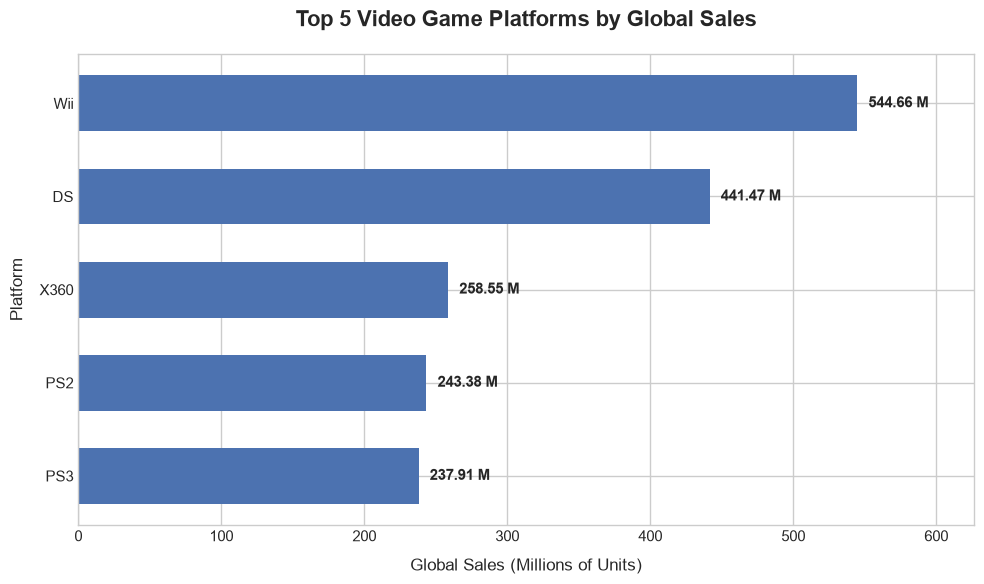

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. โหลดข้อมูลจากไฟล์ CSV
# หมายเหตุ: เปลี่ยน 'your_data.csv' ให้เป็นชื่อไฟล์จริงของคุณ
df = pd.read_excel("Game_data_clean.xlsx")

# 2. รวมยอดขายรวมทั่วโลก (Global_Sales) แยกตามแต่ละแพลตฟอร์ม
platform_sales = df.groupby("Platform")["Global_Sales"].sum().reset_index()

# 3. จัดเรียงข้อมูลจากมากไปน้อย และดึงมาเฉพาะ 5 อันดับแรก
top_5_platforms = platform_sales.sort_values(
    by="Global_Sales", ascending=False
).head(5)

# 4. ตั้งค่าฟอนต์และสไตล์ของกราฟเพื่อความสวยงาม
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# 5. สร้างกราฟแท่งแนวนอน (Horizontal Bar Chart)
bars = ax.barh(
    top_5_platforms["Platform"],
    top_5_platforms["Global_Sales"],
    color="#4C72B0",
    edgecolor="none",
    height=0.6,
)

# 6. แสดงตัวเลขยอดขายที่ปลายแท่งกราฟแต่ละแท่ง
ax.bar_label(bars, fmt="%.2f M", padding=8, fontsize=11, fontweight="bold")

# 7. ปรับแต่งรายละเอียดและชื่อหัวข้อของกราฟ
ax.set_title(
    "Top 5 Video Game Platforms by Global Sales",
    fontsize=16,
    fontweight="bold",
    pad=20,
)
ax.set_xlabel("Global Sales (Millions of Units)", fontsize=12, labelpad=10)
ax.set_ylabel("Platform", fontsize=12, labelpad=10)

# กลับด้านแกน Y เพื่อให้อันดับ 1 อยู่ด้านบนสุด
ax.invert_yaxis()

# ปรับช่วงขอบเขตของแกน X เพื่อไม่ให้ตัวเลขปลายแท่งหลุดขอบภาพ
ax.set_xlim(0, top_5_platforms["Global_Sales"].max() * 1.15)

# 8. ปรับการจัดวางและเซฟไฟล์ภาพกราฟลงเครื่อง
plt.tight_layout()
plt.savefig("top_5_platforms.png", dpi=300)
print(
    "สร้างกราฟสำเร็จแล้ว! ไฟล์ภาพถูกบันทึกในชื่อ 'top_5_platforms.png' เรียบร้อยครับ"
)